# 05 — SHAP Explainability

Analyse des contributions SHAP pour interpréter les prédictions du meilleur modèle.

Pipeline :
1. Chargement du modèle (MLflow Registry ou fichier) + données
2. TreeExplainer SHAP
3. SHAP values sur `X_test[:100]`
4. Summary Plot — importance globale (bar)
5. Waterfall Plot — première molécule toxique
6. Force Plot — première molécule non toxique
7. Visualisation 2D — coloration des atomes par contribution SHAP
8. Log des figures dans MLflow

In [24]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib
import os
from dotenv import load_dotenv
import xgboost as xgb

import shap
import mlflow
import mlflow.sklearn
import mlflow.xgboost
from mlflow.tracking import MlflowClient

from sklearn.model_selection import train_test_split

import rdkit
from rdkit import Chem
from rdkit.Chem import AllChem

load_dotenv(Path('../.env'))

PROCESSED_DIR         = Path('../data/processed')
INTERIM_DIR           = Path('../data/interim')
MODELS_DIR            = Path('../models')
FIGURES_DIR           = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TRACKING_URI          = os.getenv('MLFLOW_TRACKING_URI', 'http://localhost:5000')
EXPERIMENT_NAME       = 'drug-toxicity-classification'
REGISTERED_MODEL_NAME = 'drug-toxicity-xgboost'
RANDOM_STATE          = 42
N_SAMPLES             = 100

mlflow.set_tracking_uri(TRACKING_URI)
shap.initjs()
print(f'MLflow tracking URI : {TRACKING_URI}')

MLflow tracking URI : http://localhost:5000


## 1. Chargement

In [2]:
# Modèle — MLflow Registry (Production) avec fallback fichier
model = None
try:
    client   = MlflowClient()
    versions = client.get_latest_versions(REGISTERED_MODEL_NAME, stages=['Production'])
    if not versions:
        raise ValueError('Aucune version en stage Production dans le registry')
    source = versions[0].source
    try:
        model = mlflow.sklearn.load_model(source)
    except Exception:
        model = mlflow.xgboost.load_model(source)
    print(f'Modèle chargé depuis MLflow Registry (Production)')
except Exception as e:
    print(f'Registry : {e}')

if model is None:
    model = joblib.load(MODELS_DIR / 'best_model.pkl')
    print(f'Modèle chargé depuis : {MODELS_DIR / "best_model.pkl"}')

print(f'Type : {type(model).__name__}')

# Données
X_train = np.load(PROCESSED_DIR / 'X_train.npy')
X_test  = np.load(PROCESSED_DIR / 'X_test.npy')
y_test  = np.load(PROCESSED_DIR / 'y_test.npy')

# Noms des features (sauvegardés par notebook 03)
feature_names = pd.read_csv(PROCESSED_DIR / 'feature_names.csv')['feature'].tolist()
n_morgan = sum(1 for f in feature_names if f.startswith('morgan_'))

# SMILES du test set — re-split identique au notebook 03
df_all = pd.read_csv(INTERIM_DIR / 'combined_labeled.csv')
_, df_test_smiles = train_test_split(
    df_all, test_size=0.20, random_state=RANDOM_STATE, stratify=df_all['is_toxic']
)
df_test_smiles = df_test_smiles.reset_index(drop=True)

print(f'\nX_train      : {X_train.shape}')
print(f'X_test       : {X_test.shape}')
print(f'Features     : {len(feature_names)} ({n_morgan} Morgan + {len(feature_names) - n_morgan} RDKit)')
print(f'Test SMILES  : {len(df_test_smiles)}')

Modèle chargé depuis MLflow Registry (Production)
Type : XGBClassifier

X_train      : (7039, 2078)
X_test       : (1760, 2078)
Features     : 2078 (2048 Morgan + 30 RDKit)
Test SMILES  : 1760


## 2. Explainer SHAP

In [8]:
explainer = shap.TreeExplainer(model)
ev = explainer.expected_value
print(f'Explainer : {type(explainer).__name__}')
print(f'Expected value : {ev}')

Explainer : TreeExplainer
Expected value : [0.]


## 3. SHAP Values

In [9]:
X_explain = X_test[:N_SAMPLES]

print(f'Calcul des SHAP values sur {N_SAMPLES} molécules...')
shap_values = explainer.shap_values(X_explain)

# sklearn (RandomForest) → liste [class_0, class_1]
# XGBoost binary:logistic → tableau unique
if isinstance(shap_values, list):
    shap_toxic = shap_values[1]
    base_val   = explainer.expected_value[1]
else:
    shap_toxic = shap_values
    base_val   = float(explainer.expected_value)

print(f'Shape SHAP values : {shap_toxic.shape}')
print(f'Base value (classe toxique) : {base_val:.4f}')

Calcul des SHAP values sur 100 molécules...
Shape SHAP values : (100, 2078)
Base value (classe toxique) : 0.0489


## 4. Summary Plot — importance globale

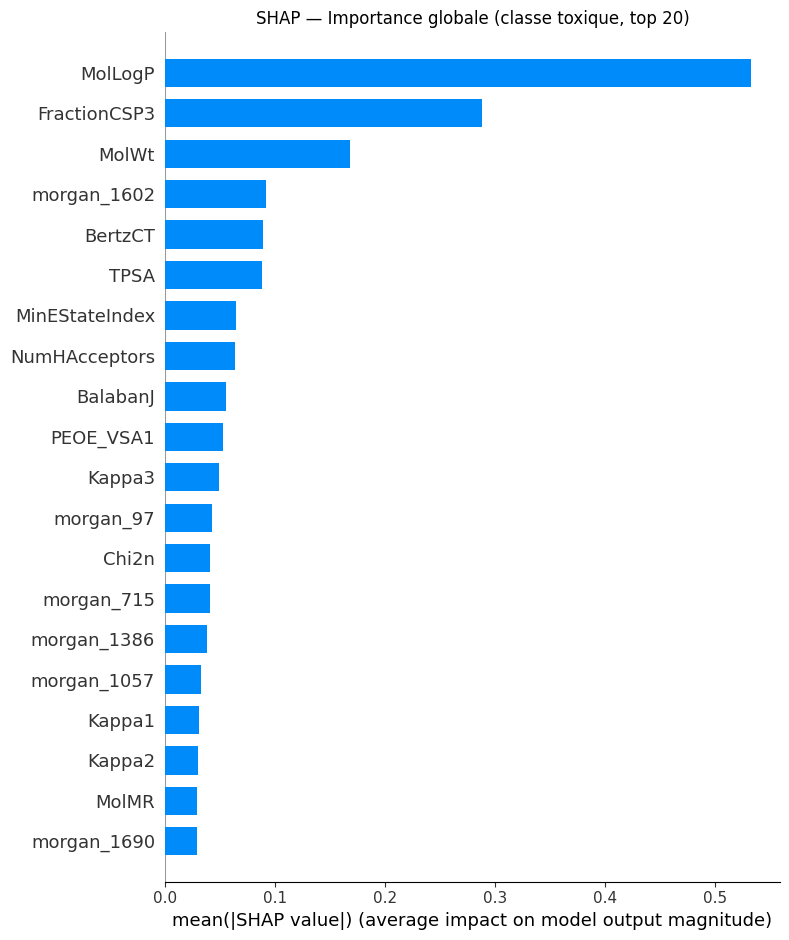

Sauvegardé : shap_summary.png


In [10]:
shap.summary_plot(
    shap_toxic,
    X_explain,
    feature_names=feature_names,
    plot_type='bar',
    max_display=20,
    show=False,
)
plt.title('SHAP — Importance globale (classe toxique, top 20)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : shap_summary.png')

## 5. Waterfall Plot — molécule toxique

Molécule toxique — indice : 0


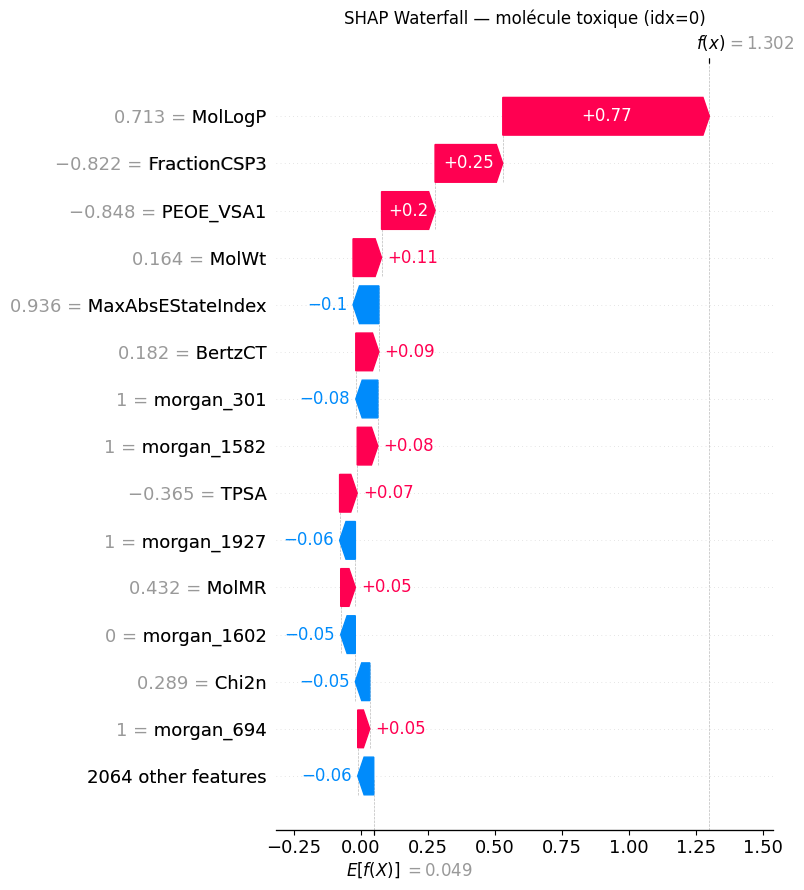

Sauvegardé : shap_waterfall.png


In [11]:
# Première molécule toxique dans X_test[:N_SAMPLES]
toxic_idx = int(np.where(y_test[:N_SAMPLES] == 1)[0][0])
print(f'Molécule toxique — indice : {toxic_idx}')

shap_exp_toxic = shap.Explanation(
    values=shap_toxic[toxic_idx],
    base_values=base_val,
    data=X_explain[toxic_idx],
    feature_names=feature_names,
)

shap.plots.waterfall(shap_exp_toxic, max_display=15, show=False)
plt.title(f'SHAP Waterfall — molécule toxique (idx={toxic_idx})')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : shap_waterfall.png')

## 6. Force Plot — molécule non toxique

Molécule non toxique — indice : 1


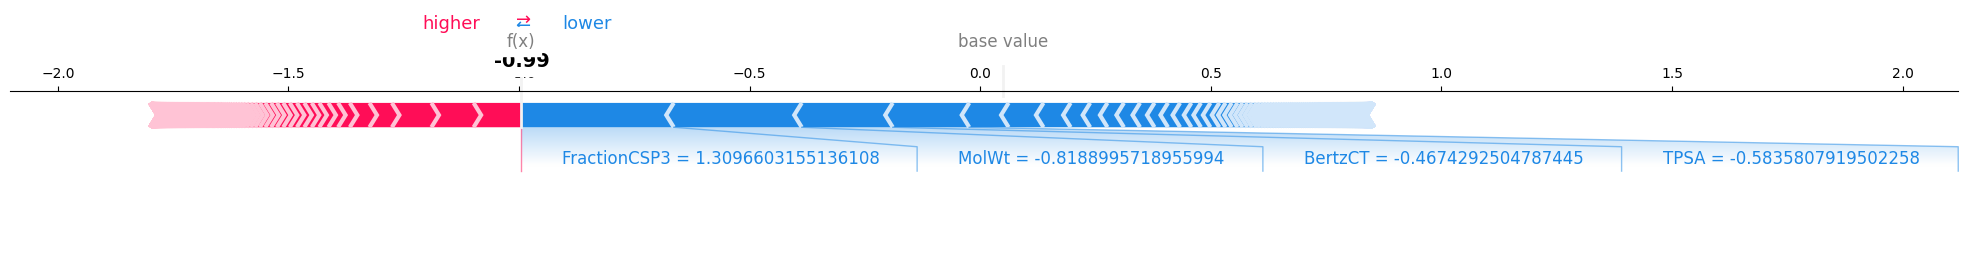

Sauvegardé : shap_force.png


In [12]:
# Première molécule non toxique dans X_test[:N_SAMPLES]
safe_idx = int(np.where(y_test[:N_SAMPLES] == 0)[0][0])
print(f'Molécule non toxique — indice : {safe_idx}')

shap.force_plot(
    base_val,
    shap_toxic[safe_idx],
    X_explain[safe_idx],
    feature_names=feature_names,
    matplotlib=True,
    show=False,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'shap_force.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : shap_force.png')

## 7. Visualisation 2D — coloration SHAP par atome

Les SHAP values des bits Morgan actifs sont agrégées par atome via le `bitInfo` de RDKit.
**Rouge** = contribution vers toxique | **Vert** = contribution vers non-toxique

In [25]:
# SMILES de la molécule toxique choisie


smiles = df_test_smiles.iloc[toxic_idx]['smiles']
mol    = Chem.MolFromSmiles(smiles)

print(f'SMILES : {smiles}')
print(f'Atomes : {mol.GetNumAtoms()}')

# Bit-info Morgan : {bit_idx: [(atom_idx, radius), ...]}
bi = {}
AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048, bitInfo=bi)

# SHAP values des bits Morgan (features 0..n_morgan-1)
shap_morgan = shap_toxic[toxic_idx, :n_morgan]

# Agrégation par atome
atom_weights = np.zeros(mol.GetNumAtoms())
for bit_idx, env_list in bi.items():
    for atom_idx, radius in env_list:
        atom_weights[atom_idx] += shap_morgan[bit_idx]

print(f'Poids SHAP atomes : min={atom_weights.min():.4f}  max={atom_weights.max():.4f}')

# Remplace juste la partie SimilarityMap
drawer = rdkit.Chem.Draw.MolDraw2DCairo(400, 400)

SimilarityMaps.GetSimilarityMapFromWeights(
    mol,
    atom_weights.tolist(),
    draw2d=drawer,
    colorMap='RdYlGn_r',
    contourLines=10,
)

drawer.FinishDrawing()

# Sauvegarder
with open(FIGURES_DIR / 'shap_molecule.png', 'wb') as f:
    f.write(drawer.GetDrawingText())

print('Sauvegardé : shap_molecule.png')

SMILES : CC(C)=CCC1C(=O)N(c2ccccc2)N(c2ccccc2)C1=O
Atomes : 24
Poids SHAP atomes : min=-0.0983  max=0.0795


[23:09:16] DEPRECATION WARNING: please use MorganGenerator


Sauvegardé : shap_molecule.png


## 8. Log des figures dans MLflow

In [ ]:
figures = {
    'shap_summary.png':   FIGURES_DIR / 'shap_summary.png',
    'shap_waterfall.png': FIGURES_DIR / 'shap_waterfall.png',
    'shap_force.png':     FIGURES_DIR / 'shap_force.png',
    'shap_molecule.png':  FIGURES_DIR / 'shap_molecule.png',
}

mlflow.set_experiment(EXPERIMENT_NAME)

with mlflow.start_run(run_name='shap_analysis'):
    mlflow.log_param('model_type',  type(model).__name__)
    mlflow.log_param('n_samples',   N_SAMPLES)
    mlflow.log_param('n_features',  len(feature_names))
    mlflow.log_param('toxic_idx',   toxic_idx)
    mlflow.log_param('safe_idx',    safe_idx)

    for name, path in figures.items():
        if path.exists():
            mlflow.log_artifact(str(path), artifact_path='shap_figures')
            print(f'  Loggé : {name}')
        else:
            print(f'  Manquant : {name}')

    run_id = mlflow.active_run().info.run_id

print(f'\nRun MLflow : {run_id}')
print(f'Figures dans : shap_figures/')